# Finite Sampling, Genetic Drift, and Mutation

Reproduce the simulations in Lecture 8. Each section names the corresponding
slide. $N$ counts diploid individuals, $K_t$ counts allele copies, and
$p_t=K_t/(2N)$. The probability-model calculations are supplied by hpgR.


In [1]:
library(hpgR)
.processes <- populationProcessExample()
options(repr.plot.width = 9, repr.plot.height = 4.2, repr.plot.pointsize = 13,
        repr.plot.bg = "white")
invisible(par(bg = "white"))
RNGkind("Mersenne-Twister", "Inversion", "Rejection")
blue <- "#265991"
orange <- "#D65F22"
red <- "#C73D28"
gray <- "#75787B"


## Draw the Next Generation in R

Five diploid individuals carry three $A$ copies. Independently sample ten
parental copies, with replacement. Then $K_{t+1}\mid p_t=0.3$ is
binomial with size 10 and probability 0.3.


In [2]:
set.seed(8149)
K <- rbinom(1, size = 10, prob = 0.3)
p.next <- K / 10
data.frame(K = K, p_next = p.next, probability_of_three = dbinom(3, 10, 0.3))


K,p_next,probability_of_three
<int>,<dbl>,<dbl>
4,0.4,0.2668279


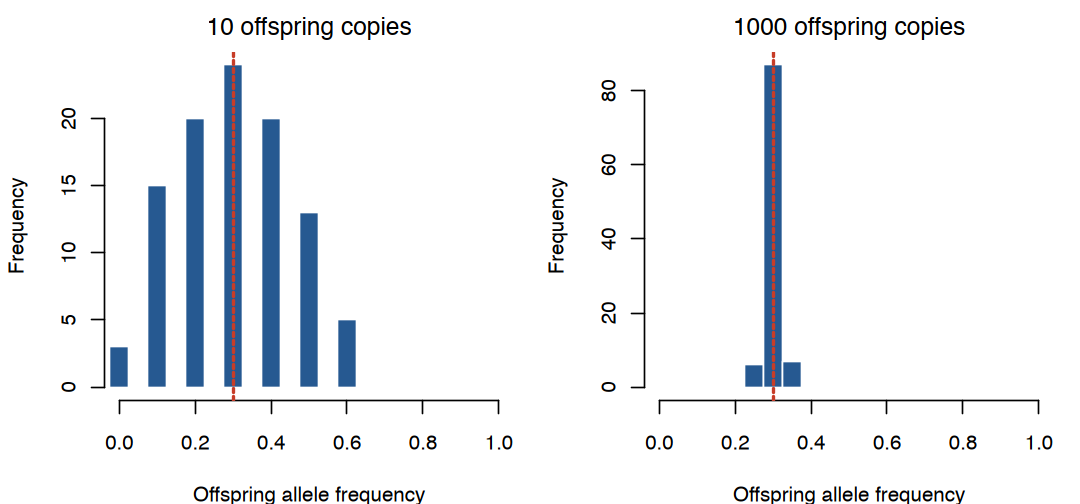

In [3]:
set.seed(8149)
small_draws <- rbinom(100, size = 10, prob = 0.3) / 10
large_draws <- rbinom(100, size = 1000, prob = 0.3) / 1000
old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
for (M in c(10, 1000)) {
    draws_here <- if (M == 10) small_draws else large_draws
    hist(draws_here, breaks = seq(-0.025, 1.025, by = 0.05), xlim = c(0, 1),
         col = blue, border = "white", xlab = "Offspring allele frequency",
         main = paste(M, "offspring copies"))
    abline(v = 0.3, col = red, lty = 2, lwd = 2)
}
par(old_par)
stopifnot(all(c(small_draws, large_draws) >= 0),
          all(c(small_draws, large_draws) <= 1))


## Sampling Builds a New Generation

Regenerate the two sampling animations using their original code and seed.
The ten explicit draws become the first update of the $N=5$ path.
**Population Size Changes the Rate of Drift** uses these same paths.
The infinite-population limit keeps $p=0.3$.


In [4]:
sampling <- samplingExample()
draws <- sampling$draws
first.count <- sum(draws <= 3L)
paths <- sampling$paths


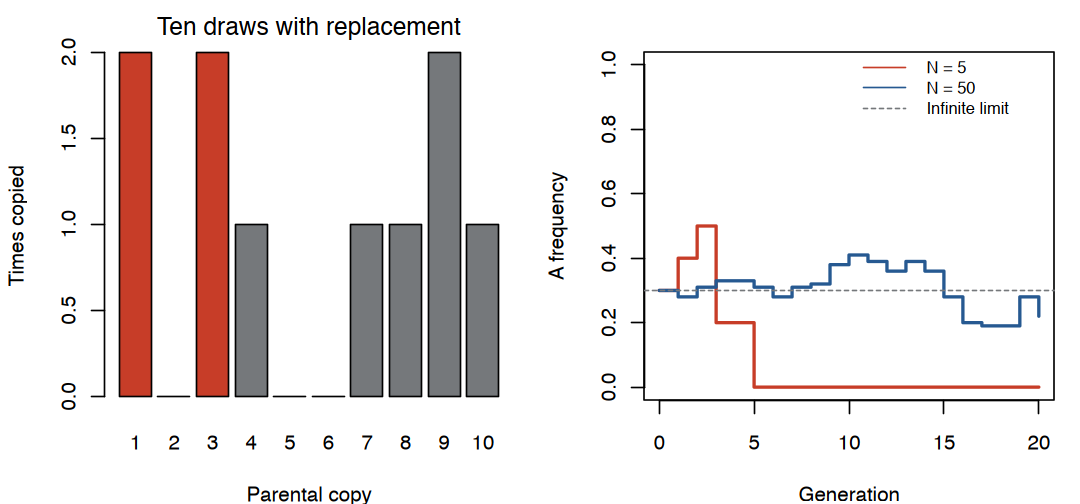

In [5]:
old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
barplot(tabulate(draws, nbins = 10), col = c(rep(red, 3), rep(gray, 7)),
        names.arg = 1:10, xlab = "Parental copy", ylab = "Times copied",
        main = "Ten draws with replacement")
plot(0:20, paths[[1]]$counts / 10, type = "s", ylim = c(0, 1),
     col = red, lwd = 2, xlab = "Generation", ylab = "A frequency")
lines(0:20, paths[[2]]$counts / 100, type = "s", col = blue, lwd = 2)
abline(h = 0.3, lty = 2, col = gray)
legend("topright", c("N = 5", "N = 50", "Infinite limit"),
       col = c(red, blue, gray), lty = c(1, 1, 2), bty = "n", cex = 0.8, y.intersp = 2)
par(old_par)
stopifnot(first.count == 4, paths[[1]]$counts[2] == first.count)


## Buri's Experiment Tests the Sampling Model

The Buri comparison in the lecture follows generations 0–19. Here 105
simulated cultures start at $p_0=0.5$, with $N=16$. Every column is an
independent culture; every row is a generation. These are model draws,
not Buri's observed cultures. The second notebook reuses these records.
The panels show generations 1–19 after the identical starting state.


In [6]:
record_N <- 16L
record_generations <- 19L
record_cultures <- 105L
recorded <- simulateFrequencyRecords(record_N, record_generations, record_cultures)
generation_counts <- recorded$counts
generation_records <- recorded$records


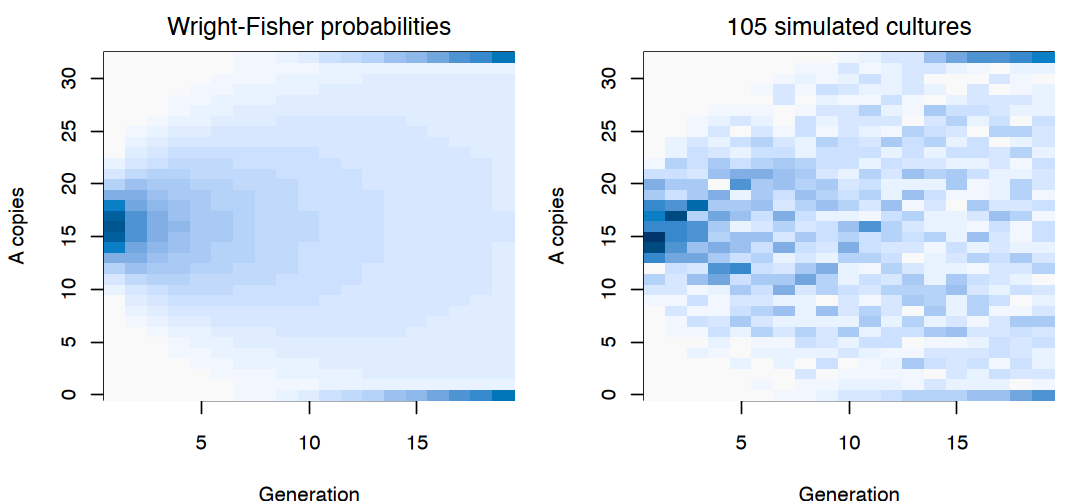

In [7]:
M <- 2L * record_N
law <- frequencyCountDistribution(record_N, record_generations)
transition <- law$transition
model_probability <- law$probability
simulated_probability <- vapply(0:M, function(k) rowMeans(generation_counts == k),
                               numeric(record_generations + 1L))
old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
probability_range <- c(0, max(model_probability[-1, ], simulated_probability[-1, ]))
for (panel in 1:2) {
    item <- if (panel == 1) model_probability else simulated_probability
    image(1:record_generations, 0:M, item[-1, ],
          col = hcl.colors(24, "Blues 3", rev = TRUE),
          xlab = "Generation", ylab = "A copies", zlim = probability_range,
          main = c("Wright-Fisher probabilities", "105 simulated cultures")[panel])
}
par(old_par)
stopifnot(max(abs(rowSums(transition) - 1)) < 1e-12,
          max(abs(rowSums(model_probability) - 1)) < 1e-12)


## Frequency Differences Accumulate across Generations

Reproduce the lecture's curves at $p_0=0.5$, $N=16,100$:

$$V_t=p_0(1-p_0)[1-(1-1/(2N))^t],\qquad
H_t=2p_0(1-p_0)(1-1/(2N))^t.$$

These are expectations across replicate populations, not individual paths.


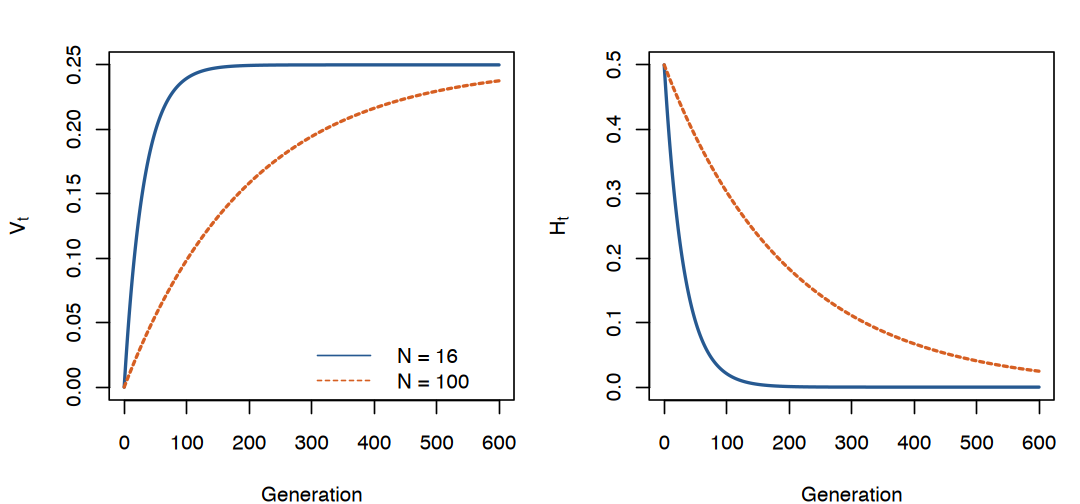

In [8]:
time <- 0:600
sizes <- c(16, 100)
moments <- driftMoments(sizes, time)
variance_curve <- moments$variance
diversity_curve <- moments$diversity
old_par <- par(mfrow = c(1, 2), mar = c(4, 4.2, 2, 1), bg = "white")
matplot(time, variance_curve, type = "l", col = c(blue, orange), lty = 1:2,
        lwd = 2, xlab = "Generation", ylab = expression(V[t]))
legend("bottomright", paste("N =", sizes), col = c(blue, orange), lty = 1:2,
       bty = "n", y.intersp = 2)
matplot(time, diversity_curve, type = "l", col = c(blue, orange), lty = 1:2,
        lwd = 2, xlab = "Generation", ylab = expression(H[t]))
par(old_par)
stopifnot(max(abs(2 * variance_curve + diversity_curve - 0.5)) < 1e-12)


## Population Recovery Copies the Surviving Alleles

Reproduce the bottleneck animation: five states at $N=10$, two at $N=3$,
then five at $N=10$. Generation 0 contains 20 different founder alleles.
Mutation is off. The code records each parental-copy choice.


In [9]:
bottleneck <- .processes$bottleneck


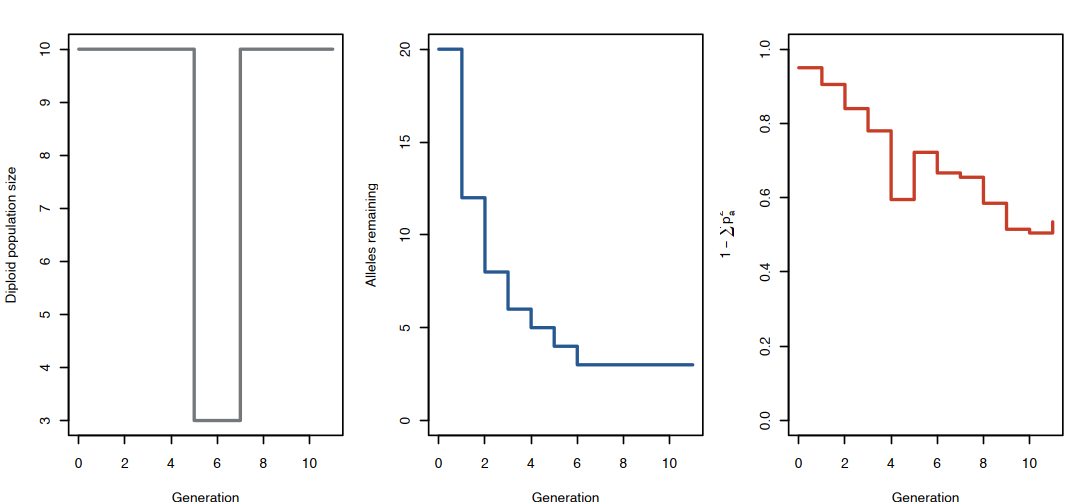

In [10]:
g <- seq_along(bottleneck$sizes) - 1L
old_par <- par(mfrow = c(1, 3), mar = c(4, 4, 2, 1), bg = "white")
plot(g, bottleneck$sizes, type = "s", lwd = 2, col = gray,
     xlab = "Generation", ylab = "Diploid population size")
plot(g, bottleneck$allele_counts, type = "s", lwd = 2, col = blue,
     xlab = "Generation", ylab = "Alleles remaining", ylim = c(0, 20))
plot(g, bottleneck$heterozygosity, type = "s", lwd = 2, col = red,
     xlab = "Generation", ylab = expression(1 - sum(p[a]^2)), ylim = c(0, 1))
par(old_par)
stopifnot(all(diff(bottleneck$allele_counts) <= 0),
          tail(bottleneck$allele_counts, 1) == 3L)


## The Fate of a New Mutation

Recreate the setting of Pritchard's Fig. 2.9: 200 independent new mutations
introduced at random generations, each starting as one of 100 copies
($2N=100$, as labeled in the figure). Use a new seed, so these are new
trajectories under the same model. Each lineage subsequently follows drift
alone. Variants still segregating at generation 1000 remain unresolved.



             Lost             Fixed Still segregating 
              198                 1                 1 

first_generation_loss eventual_fixation_probability 
                    0.3660323                     0.0100000

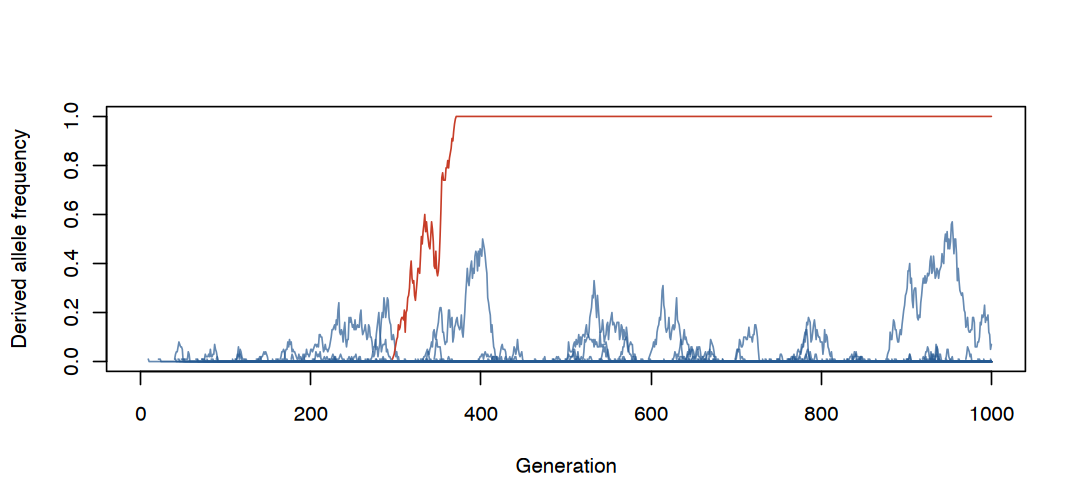

In [11]:
mutation_copies <- 100L
mutation_replicates <- 200L
fates <- simulateNewMutationPaths(mutation_copies, mutation_replicates)
introduction <- fates$introduction
mutation_paths <- fates$paths
invisible(par(bg = "white"))
mutation_colors <- rep(grDevices::adjustcolor(blue, alpha.f = 0.7), mutation_replicates)
mutation_colors[mutation_paths[1001, ] == 1] <- red
matplot(0:1000, mutation_paths, type = "l", lty = 1,
        col = mutation_colors,
        xlab = "Generation", ylab = "Derived allele frequency", ylim = c(0, 1))
mutation_frequency <- mutation_paths[1001, ]
table(factor(ifelse(mutation_frequency == 0, "Lost",
                    ifelse(mutation_frequency == 1, "Fixed", "Still segregating")),
             levels = c("Lost", "Fixed", "Still segregating")))
c(first_generation_loss = dbinom(0, mutation_copies, 1 / mutation_copies),
  eventual_fixation_probability = 1 / mutation_copies)
stopifnot(!anyNA(mutation_frequency), all(mutation_frequency >= 0 & mutation_frequency <= 1))


## Mutation and Drift Keep Alleles Turning Over

Reproduce the animation at one locus: $N=5$, $\mu=0.10$ per copy per
generation, initially one allele. Every mutation receives a new allele ID.
For the raw finite-pool diversity $h=1-\sum_a p_a^2$, this model gives

$$E(h_{t+1}\mid h_t)=(1-1/(2N))[1-(1-\mu)^2(1-h_t)].$$

Here the update is $0.171+0.729h_t$. Its stationary mean is $171/271$.
The lecture's small-mutation approximation $H\approx4N\mu$ does not apply
at these settings; $\mu$ here is per locus, not a human per-base rate.


In [12]:
mutation <- .processes$mutation


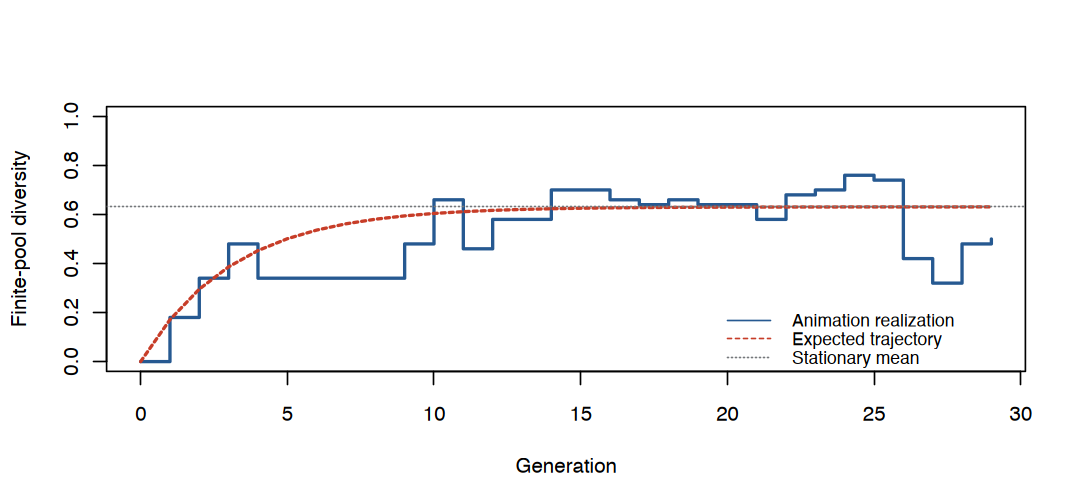

In [13]:
mu <- mutation$mu
N <- mutation$sizes[1]
a <- (1 - 1 / (2 * N)) * (1 - mu)^2
b <- (1 - 1 / (2 * N)) * (1 - (1 - mu)^2)
expected_h <- numeric(length(mutation$copies))
for (t in seq_len(length(expected_h) - 1L)) expected_h[t + 1L] <- b + a * expected_h[t]
g <- seq_along(expected_h) - 1L
invisible(par(bg = "white"))
plot(g, mutation$heterozygosity, type = "s", lwd = 2, col = blue,
     ylim = c(0, 1), xlab = "Generation", ylab = "Finite-pool diversity")
lines(g, expected_h, col = red, lwd = 2, lty = 2)
abline(h = b / (1 - a), col = gray, lty = 3)
legend("bottomright", c("Animation realization", "Expected trajectory", "Stationary mean"),
       col = c(blue, red, gray), lty = 1:3, bty = "n", cex = 0.85, y.intersp = 2)
stopifnot(abs(a - 0.729) < 1e-12, abs(b - 0.171) < 1e-12,
          abs(b / (1 - a) - 171 / 271) < 1e-12,
          tail(mutation$heterozygosity, 1) == 0.5)


## How Two Copies Become IBD

Reproduce the animation's ten separately identified founder copies and
recorded parental choices. The final pair was specified before simulation.
Matching founder IDs measure founder-relative IBD; these IDs are retained
simulation records, not IBD inferred from sequence similarity.


In [14]:
ancestry <- .processes$ancestry


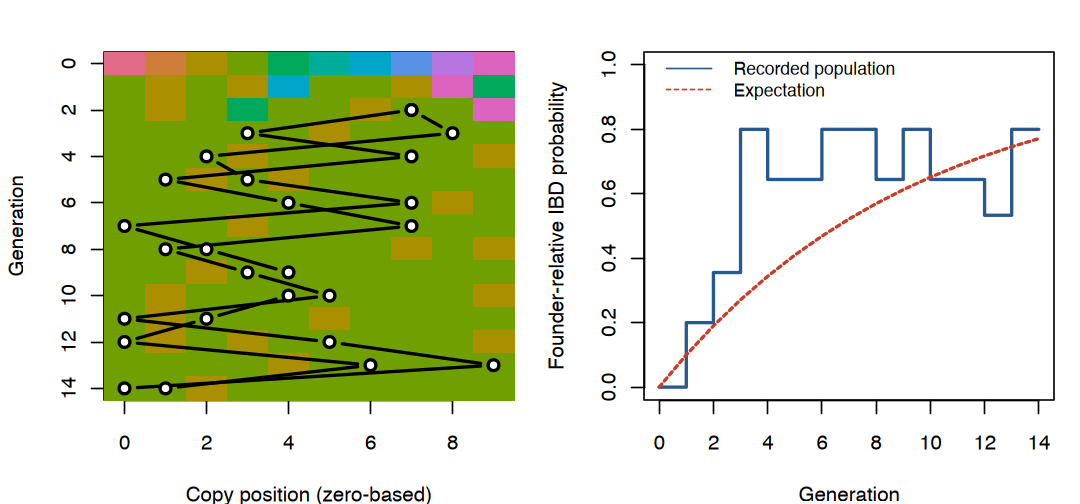

In [15]:
founder_matrix <- do.call(rbind, ancestry$copies)
palette <- hcl.colors(10, "Dark 3")
old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
image(0:9, 0:14, t(founder_matrix), col = palette, breaks = seq(0.5, 10.5, 1),
      ylim = c(14.5, -0.5), xlab = "Copy position (zero-based)", ylab = "Generation")
pair_trace <- do.call(rbind, ancestry$backward_trace)
for (i in 1:2) {
    lines(pair_trace[, i], 14 - seq_len(nrow(pair_trace)) + 1L,
          type = "b", pch = 21, bg = "white", col = "black", lwd = 2)
}
realized_F <- apply(founder_matrix, 1, function(x) {
    counts <- table(x)
    sum(counts * (counts - 1)) / (length(x) * (length(x) - 1))
})
plot(0:14, realized_F, type = "s", col = blue, lwd = 2, ylim = c(0, 1),
     xlab = "Generation", ylab = "Founder-relative IBD probability")
lines(0:14, 1 - (1 - 1 / 10)^(0:14), col = red, lty = 2, lwd = 2)
legend("topleft", c("Recorded population", "Expectation"), col = c(blue, red),
       lty = 1:2, bty = "n", cex = 0.85, y.intersp = 2)
par(old_par)
stopifnot(ancestry$meeting_generation == 2L,
          max(abs(1 - realized_F - ancestry$heterozygosity / 0.9)) < 1e-12)


## Finite Inheritance Can Create LD

Reproduce the slide's parental frequencies and displayed offspring draw.
$D=f_{AB}-p_Ap_B$. The offspring counts are a possible multinomial outcome,
not a deterministic consequence of copying whole haplotypes.


In [16]:
haplotype <- c("AB", "Ab", "aB", "ab")
parent_frequency <- rep(0.25, 4)
offspring_count <- c(3, 1, 1, 3)
offspring_frequency <- offspring_count / sum(offspring_count)

data.frame(haplotype, parental_frequency = parent_frequency,
           displayed_offspring_count = offspring_count,
           offspring_frequency = offspring_frequency)
c(parental_D = ld(parent_frequency), offspring_D = ld(offspring_frequency),
  probability_of_displayed_draw = dmultinom(offspring_count, prob = parent_frequency))
stopifnot(ld(parent_frequency) == 0, ld(offspring_frequency) == 1 / 8)


haplotype,parental_frequency,displayed_offspring_count,offspring_frequency
<chr>,<dbl>,<dbl>,<dbl>
AB,0.25,3,0.375
Ab,0.25,1,0.125
aB,0.25,1,0.125
ab,0.25,3,0.375


parental_D                   offspring_D probability_of_displayed_draw 
                   0.00000000                    0.12500000                    0.01708984

## Recombination Cuts the Shared Ancestral Segment

Reproduce the animation on a one-Morgan region, conditional on retaining
the ancestral copy at its central site. Twelve meioses alternate between
two descendant paths. Breakpoints follow a Poisson process with mean one
per meiosis. This focal-containing interval is not a randomly chosen tract.


In [17]:
focal <- .5
recombination <- .processes$recombination


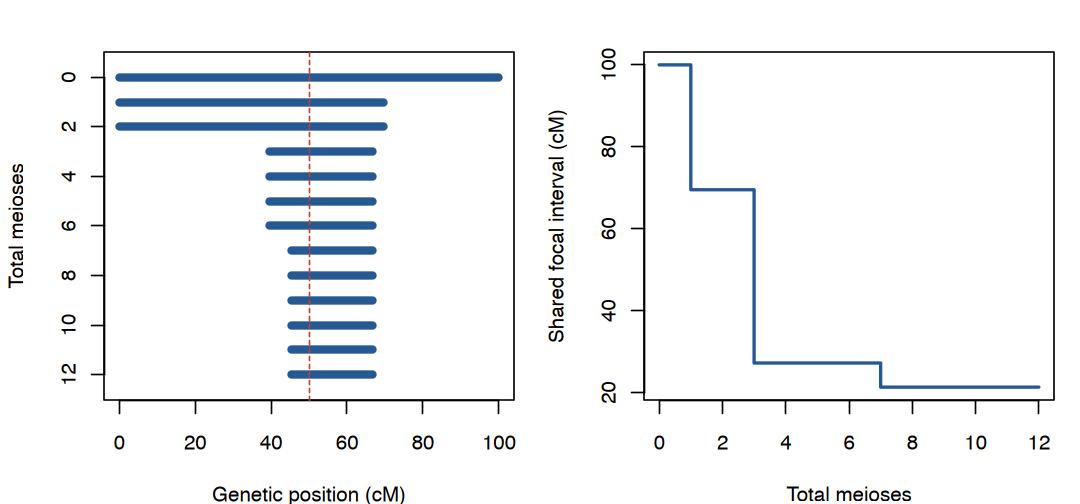

In [18]:
meiosis <- vapply(recombination, function(s) s$m, 0L)
shared <- t(vapply(recombination, function(s) s$shared, numeric(2)))
old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
plot(NA, xlim = c(0, 100), ylim = c(12.5, -0.5),
     xlab = "Genetic position (cM)", ylab = "Total meioses")
segments(100 * shared[, 1], meiosis, 100 * shared[, 2], meiosis,
         col = blue, lwd = 5)
abline(v = 100 * focal, col = red, lty = 2)
plot(meiosis, 100 * (shared[, 2] - shared[, 1]), type = "s", col = blue, lwd = 2,
     xlab = "Total meioses", ylab = "Shared focal interval (cM)")
par(old_par)
stopifnot(all(shared[, 1] <= focal), all(shared[, 2] >= focal),
          all(diff(shared[, 2] - shared[, 1]) <= 0))


Sources: Pritchard, [Sec. 2.1 and Sec. 2.3](https://web.stanford.edu/group/pritchardlab/HGbook.html);
Gorroochurn, Secs. 8.2–8.9; Láruson and Reed, Ch. 6;
Coop, [Ch. 4](https://github.com/cooplab/popgen-notes).
The six animation calculations use the lecture's original state generators.
The mutation trajectories recreate Fig. 2.9 with a new seed and uniformly
sampled introduction times, using the plotted copy count $2N=100$.
The Buri comparison uses 105 simulated cultures and 19 updates; observed
experimental frequencies are shown separately in the lecture.
